Review Decision values:
Review Decision
agree       2272996
disagree     576282
<NA>              1
Name: count, dtype: Int64
Training Logistic Regression...


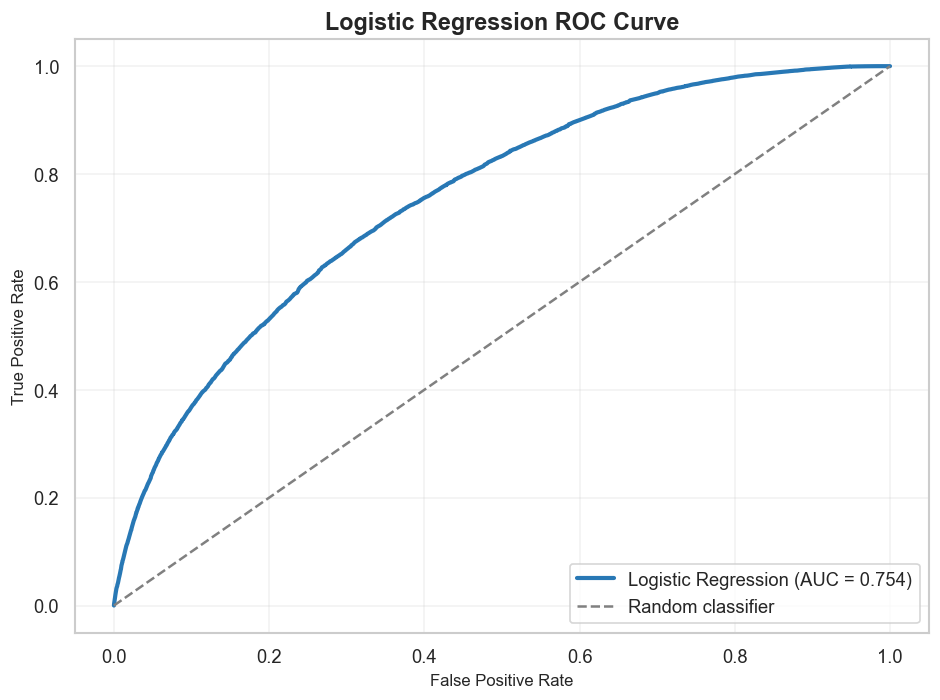

Logistic Regression ROC-AUC: 0.754
Training Random Forest...


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.inspection import permutation_importance


TARGET = "Review Decision"

predictors = [
    "Part",
    "DRG",
    "HCPCS Procedure Code",
    "Provider Type",
    "Type of Bill",
    "Source_Year",
]

missing = [c for c in [TARGET] + predictors if c not in data.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df = data[[TARGET] + predictors].copy()

df[TARGET] = df[TARGET].astype("string").str.strip().str.lower()

print("Review Decision values:")
print(df[TARGET].value_counts(dropna=False))

df["Target"] = df[TARGET].map({
    "agree": 0,
    "disagree": 1,
})

df = df.dropna(subset=["Target"]).copy()
df["Target"] = df["Target"].astype(int)

if df["Target"].nunique() != 2:
    raise ValueError(
        "Could not find both Agree and Disagree. "
        "Check the Review Decision values printed above."
    )

X = df[predictors].copy()
y = df["Target"]

categorical_cols = [
    "Part",
    "DRG",
    "HCPCS Procedure Code",
    "Provider Type",
    "Type of Bill",
    "Source_Year",
]

for col in categorical_cols:
    X[col] = X[col].astype("string").fillna("Missing")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

logistic_preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])

logistic_model = Pipeline([
    ("preprocessor", logistic_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    )),
])

print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)

logistic_probs = logistic_model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, logistic_probs)
auc = roc_auc_score(y_test, logistic_probs)


fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr,
    tpr,
    color="#2878B5",
    linewidth=2.5,
    label=f"Logistic Regression (AUC = {auc:.3f})",
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier",
)

ax.set_title("Logistic Regression ROC Curve", fontsize=14)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("logistic_regression_roc.png", dpi=300)
plt.show()

print(f"Logistic Regression ROC-AUC: {auc:.3f}")


rf_preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

rf_auc = roc_auc_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1],
)

print(f"Random Forest ROC-AUC: {rf_auc:.3f}")

if len(X_test) > 20000:
    sample_indices = (
        y_test.groupby(y_test, group_keys=False)
        .sample(n=10000, random_state=42)
        .index
    )
    X_imp = X_test.loc[sample_indices]
    y_imp = y_test.loc[sample_indices]
else:
    X_imp = X_test
    y_imp = y_test

importance_result = permutation_importance(
    rf_model,
    X_imp,
    y_imp,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1,
)

importance = pd.Series(
    importance_result.importances_mean,
    index=predictors,
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    importance.index,
    importance.values,
    color="#299D8F",
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(
    "Random Forest Feature Importance",
    fontsize=14,
)
ax.set_xlabel(
    "Decrease in average precision after shuffling"
)
ax.set_ylabel("Predictor")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig("random_forest_feature_importance.png", dpi=300)
plt.show()

print("\nSaved:")
print("logistic_regression_roc.png")
print("random_forest_feature_importance.png")
